# AI-Assisted Web Application Penetration Testing — walkthrough

A short, runnable tour of the project on **CIC-IDS2017** (web-attack day):
1. load the cleaned HTTP-flow dataset,
2. train an AI detector and evaluate it on held-out flows,
3. see why the conventional threshold IDS misses the attacks,
4. check what the models are really learning (payload-less artifact flows),
5. review the results of the full experiment suite.

Run `python src/download_data.py` first (it downloads, verifies and preprocesses the data). The full experiments are in `src/` (`python src/run_all.py`).

In [1]:
import sys, json
from pathlib import Path
import pandas as pd
ROOT = Path.cwd().parent                      # this notebook lives in notebooks/
sys.path.insert(0, str(ROOT / "src"))
import config, data as D, metrics as Mx, models as M
from baseline import ThresholdIDS

profile = json.loads(config.PROFILE_JSON.read_text())["thursday"]
print(f"raw flows {profile['raw_rows']:,} -> unique {profile['after_dedup_rows']:,} -> HTTP flows {profile['http_rows']:,}")

raw flows 170,366 -> unique 164,179 -> HTTP flows 19,725


## 1. The data
HTTP (port 80) flows from Thursday morning, 66 CICFlowMeter statistics per flow.

In [2]:
df = D.load_http()
X, labels, y = D.xy(df)
print(pd.Series(labels).value_counts().to_string())
X[["Flow Duration", "Total Fwd Packets", "Total Length of Fwd Packets", "Fwd IAT Min", "Init_Win_bytes_forward"]].describe().round(1)

BENIGN           17582
Brute Force       1470
XSS                652
SQL Injection       21


,Flow Duration,Total Fwd Packets,Total Length of Fwd Packets,Fwd IAT Min,Init_Win_bytes_forward
count,19725.0,19725.0,19725.0,19725.0,19725.0
mean,32219545.2,75.4,1205.5,264033.8,15317.1
std,45541067.4,3278.3,19798.6,3295810.0,14766.5
min,-1.0,1.0,0.0,0.0,0.0
25%,80960.0,3.0,6.0,102.0,8192.0
50%,5525327.0,3.0,12.0,684.0,8192.0
75%,60564295.0,13.0,528.0,23377.0,29200.0
max,119999910.0,200755.0,1197199.0,120000000.0,65535.0


## 2. Train an AI detector
Stratified 80/20 split (by attack type), Random Forest, evaluation on the unseen 20%.

In [3]:
tr, te = D.split_indices(labels)
rf = M.fit("rf", M.build_models()["rf"], X.iloc[tr], y[tr])
pred, score = rf.predict(X.iloc[te]), M.attack_score(rf, X.iloc[te])
m = Mx.binary_metrics(y[te], pred, score)
print({k: round(m[k], 4) for k in ["precision", "recall", "f1", "roc_auc", "fpr", "tpr_at_1pct_fpr"]})
print("detection rate by attack type:", {k: round(v, 3) for k, v in Mx.recall_by_attack(labels[te], pred).items()})

{'precision': 1.0, 'recall': 0.986, 'f1': 0.993, 'roc_auc': 1.0, 'fpr': 0.0, 'tpr_at_1pct_fpr': 1.0}
detection rate by attack type: {'Brute Force': 0.997, 'XSS': 0.962, 'SQL Injection': 1.0}


## 3. The conventional baseline: a statistical threshold IDS
It profiles benign traffic and alarms when a flow has many metrics outside the normal range (alarm budget: 1% false positives).

In [4]:
ids = ThresholdIDS().fit(X.iloc[tr], y[tr])
s = ids.decision_function(X.iloc[te])
print(f"alarm threshold: >= {ids.m_} out-of-range metrics")
print("highest score of any attack flow:", int(s[y[te] == 1].max()), "| attacks detected:", int(ids.predict(X.iloc[te])[y[te] == 1].sum()))
alarm = X.iloc[te][(y[te] == 0) & (s >= ids.m_)].iloc[0]
print("example (benign) alarm explained:", [f"{n}={v:,.0f}" for n, v, lo, hi in ids.explain(alarm.values, list(X.columns))[:4]])

alarm threshold: >= 8 out-of-range metrics
highest score of any attack flow: 5 | attacks detected: 0
example (benign) alarm explained: ['Total Fwd Packets=1,015', 'Total Backward Packets=1,445', 'Total Length of Fwd Packets=13,564', 'Total Length of Bwd Packets=2,698,141']


## 4. What are the models really learning?
Most flows labelled as attacks carry **no payload** (TCP connection fragments), and they share the attacker's TCP initial window (29,200).

In [5]:
fwd = X["Total Length of Fwd Packets"]
pd.DataFrame({
    "flows": pd.Series(labels).value_counts(),
    "no payload": pd.Series(fwd.values == 0, index=labels).groupby(level=0).mean().round(3),
    "TCP window 29200": pd.Series(X["Init_Win_bytes_forward"].values == 29200, index=labels).groupby(level=0).mean().round(3),
}).loc[config.CLASSES]

,flows,no payload,TCP window 29200
BENIGN,17582,0.154,0.253
Brute Force,1470,0.897,0.928
XSS,652,0.963,0.965
SQL Injection,21,0.429,0.571


## 5. Results of the full experiment suite
Produced by `src/run_all.py` (5-fold cross-validation, robustness tests, validity audit).

In [6]:
cv = json.loads((config.RESULTS_DIR / "metrics.json").read_text())["cv"]
va = json.loads((config.RESULTS_DIR / "validity_audit.json").read_text())["settings"]
rows = []
for n in config.ML_MODELS + [config.BASELINE]:
    rows.append({"detector": config.DISPLAY[n],
                 "detection F1 (CV)": round(cv["binary"][n]["f1_mean"], 3),
                 "attack-type macro-F1 (CV)": round(cv["multiclass"][n]["macro_f1_mean"], 3) if n in cv["multiclass"] else None,
                 "F1, real requests & no fingerprint (S3)": round(va["S3"]["binary"][n]["f1"], 3)})
pd.DataFrame(rows)

,detector,detection F1 (CV),attack-type macro-F1 (CV),"F1, real requests & no fingerprint (S3)"
0,Logistic Regression,0.959,0.572,0.741
1,Linear SVM,0.973,0.539,0.810
2,Random Forest,0.993,0.679,0.968
3,Gradient-Boosted Trees (HistGB),0.998,0.777,0.947
4,Neural Network (MLP),0.986,0.519,0.909
5,Threshold IDS (conventional),0.000,NaN,0.000


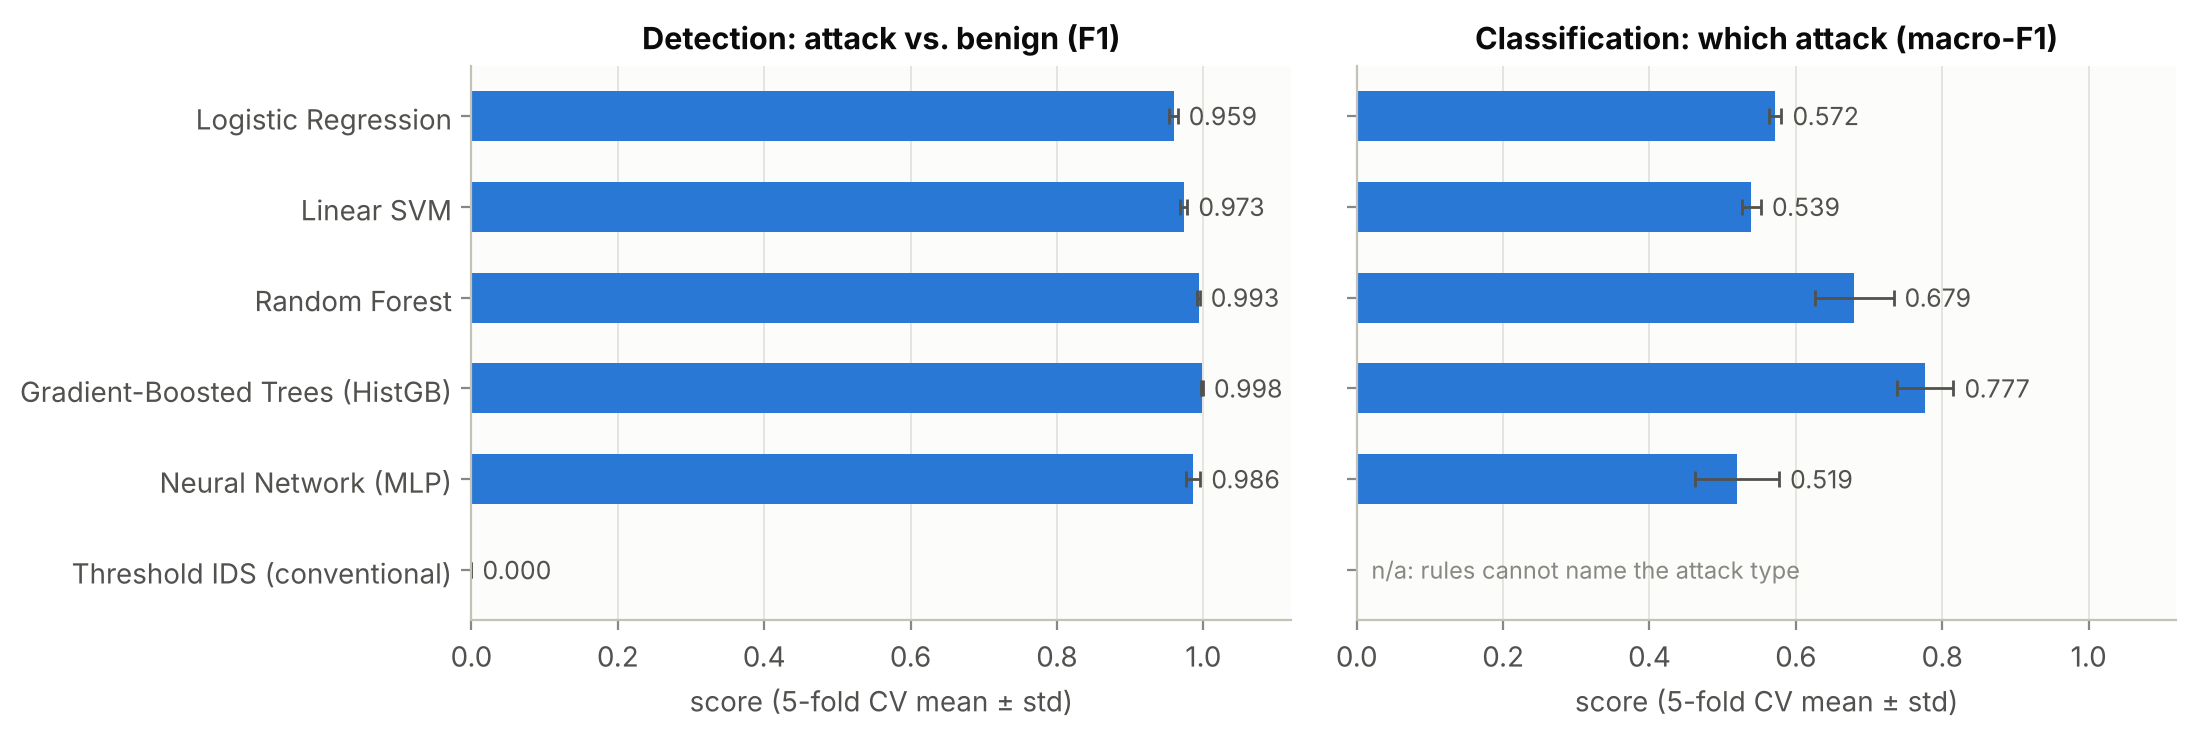

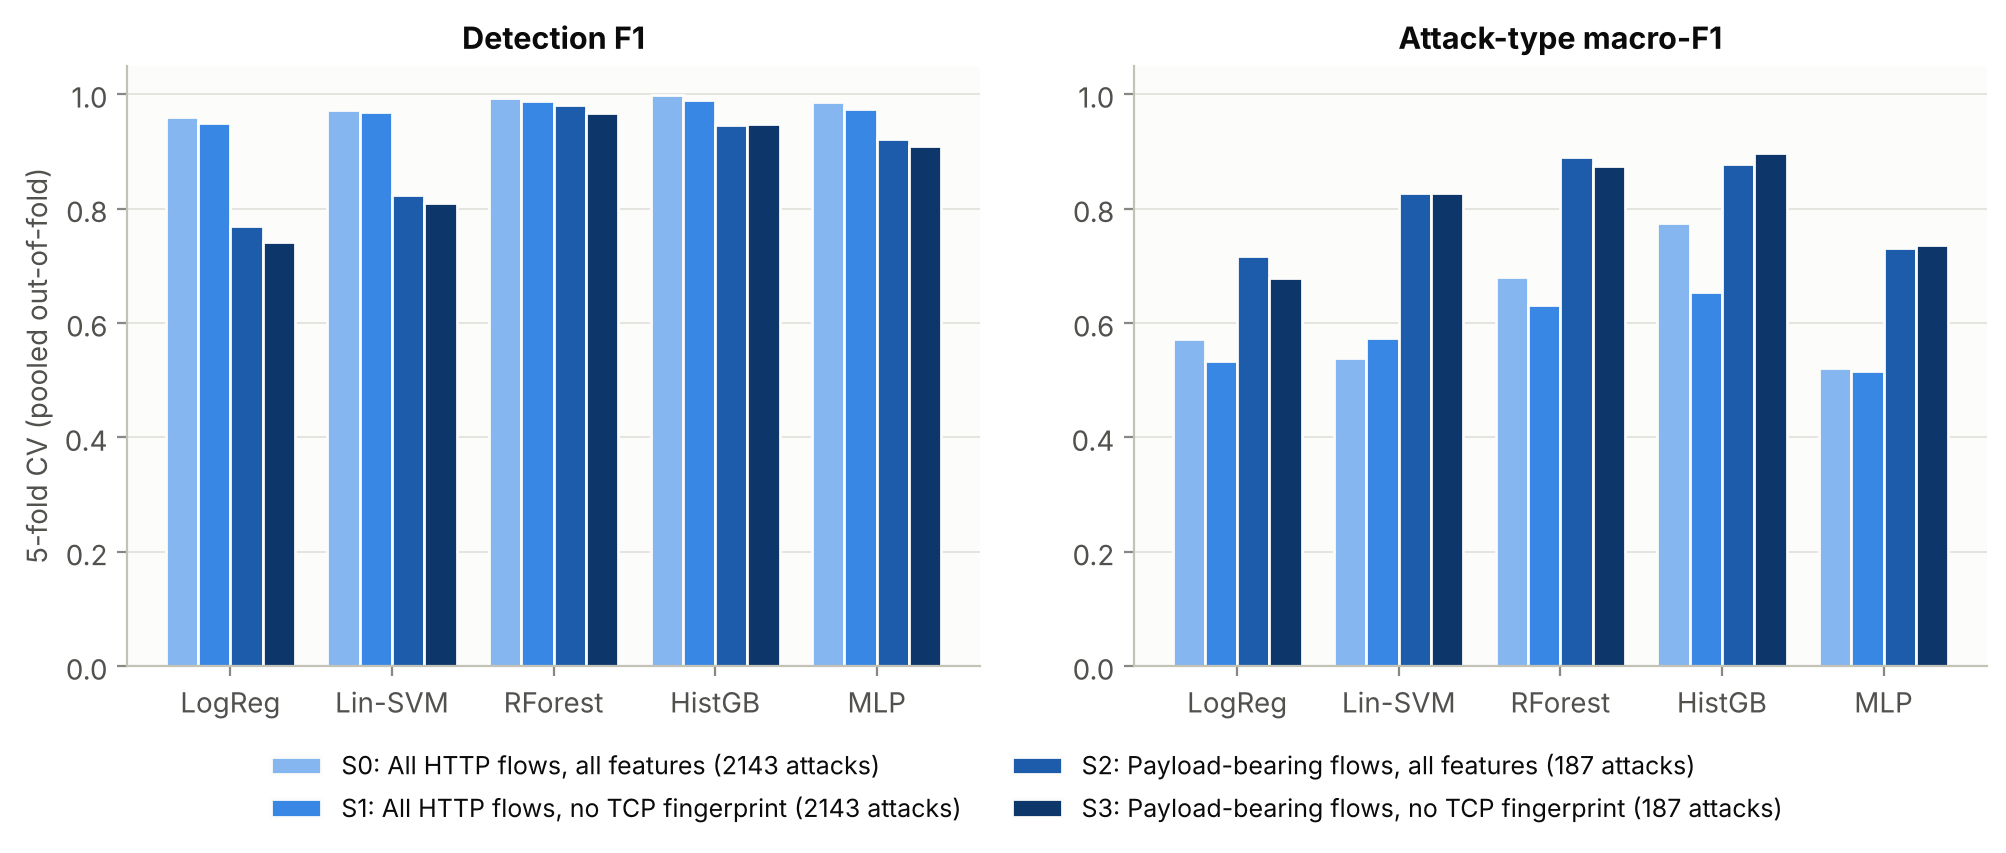

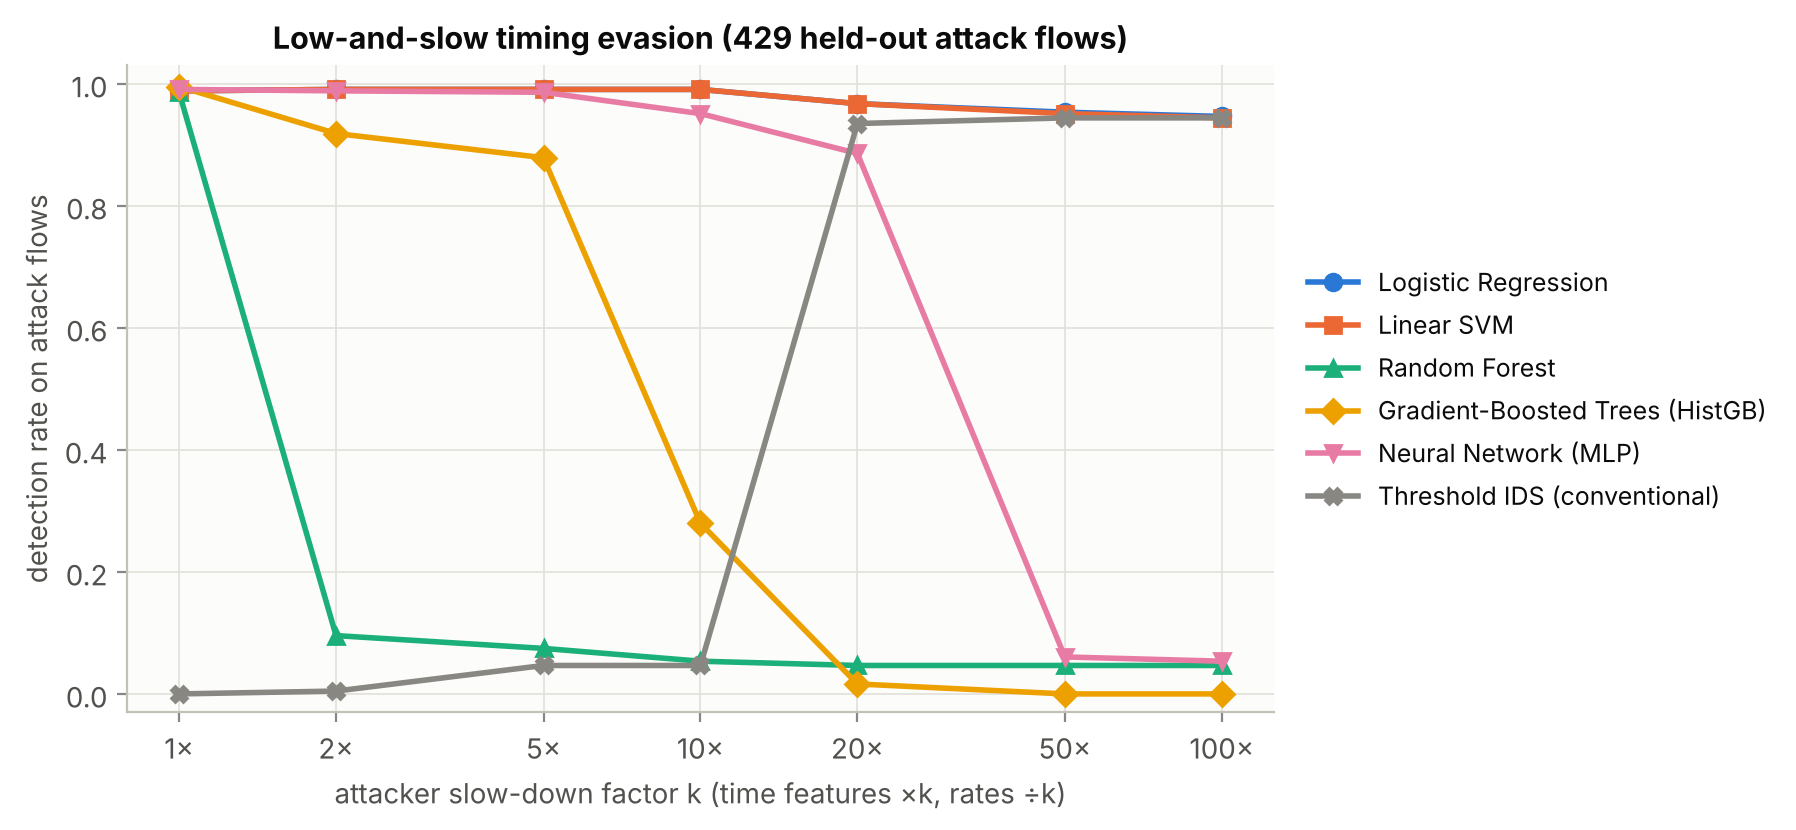

In [7]:
from IPython.display import Image, display
for f in ["fig02_detect_vs_classify.png", "fig05_validity_audit.png", "fig08_timing_evasion.png"]:
    display(Image(filename=str(config.FIG_DIR / f)))